## Sampling

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import corner

def sin2(x):
    return np.arccos(2.*x-1.) / 2.

def sin(x):
    return np.arccos(2.*x - 1.)

In [2]:
samples_1 = np.random.uniform(0, 1, 10000)
samples_2 = np.random.uniform(0, 1, 10000)
samples_3 = np.random.uniform(0, 1, 10000)
samples_4 = np.random.uniform(0, 1, 10000)

pos_theta = sin(samples_1)
pos_phi = samples_2 * 2. * np.pi

pos_x = np.sin(pos_theta) * np.cos(pos_phi)
pos_y = np.sin(pos_theta) * np.sin(pos_phi)
pos_z = np.cos(pos_theta)

nadir_theta = sin2(samples_3)
nadir_phi = samples_4 * 2. * np.pi

local_x = np.sin(nadir_theta) * np.cos(nadir_phi)
local_y = np.sin(nadir_theta) * np.sin(nadir_phi)
local_z = -np.cos(nadir_theta)

p_dir_x = local_x * np.cos(pos_theta) * np.cos(pos_phi) - local_y * np.sin(pos_phi)+local_z * np.sin(pos_theta) * np.cos(pos_phi)
p_dir_y = local_x * np.cos(pos_theta) * np.sin(pos_phi) + local_y * np.cos(pos_phi) + local_z * np.sin(pos_theta) * np.sin(pos_phi)
p_dir_z = -local_x * np.sin(pos_theta) + local_z * np.cos(pos_theta)

omega = np.pi - np.arccos(pos_x*p_dir_x+ pos_y*p_dir_y + pos_z*p_dir_z)

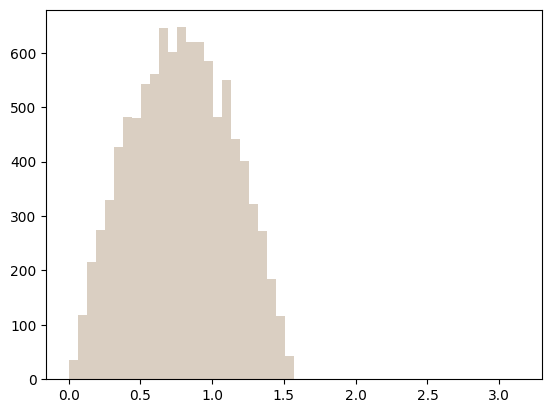

In [3]:
plt.hist(omega, bins=50, range=(0, np.pi), alpha=0.2)
plt.hist(nadir_theta, bins=50, range=(0, np.pi), alpha=0.2)
plt.show()

In [4]:
p_mom_x = - p_dir_x * np.cos(pos_theta) * np.cos(pos_phi) - p_dir_y * np.cos(pos_theta) * np.sin(pos_phi) + p_dir_z * np.sin(pos_theta)
p_mom_y =  p_dir_x * np.sin(pos_phi) - p_dir_y * np.cos(pos_phi)
p_mom_z = p_dir_x * np.sin(pos_theta) * np.cos(pos_phi) + p_dir_y * np.sin(pos_theta) * np.sin(pos_phi) +p_dir_z * np.cos(pos_theta)

p_mom_theta = np.arccos(p_mom_z / np.sqrt(p_mom_x**2 + p_mom_y**2 + p_mom_z**2))
p_mom_phi = np.arctan2(p_mom_y, p_mom_x)


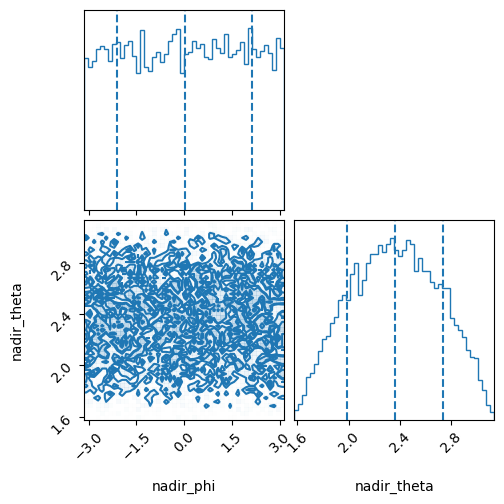

In [5]:
p_mom = np.array([p_mom_phi, p_mom_theta]).T
corner.corner(p_mom, labels=['nadir_phi', 'nadir_theta'], quantiles=[0.16, 0.5, 0.84], bins=50, color='C0', plot_datapoints=False)
plt.show()